<a href="https://colab.research.google.com/github/drabastomek/datagen/blob/choice_sim/domino_draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [174]:
import cupy as cp
import cudf

# The problem
Client: There should be 200 alternatives + 1 outside good. The outside good is always available. We'll make a slight change to how the other alternatives appear in the data. Their availability can be governed by independent binomial distributions with 50% probability. For each individual, 200 draws from a binomial distribution will correspond to the availability of the 200 alternatives. The key here is we want widely varying choice sets. Some users might be choosing between 3 options whereas others are choosing between 190 options.


### 1. Define the variables of our problem

In [175]:
n_alternatives = 200
n_alternatives_total = n_alternatives + 1 #including outside good
n_users = 100000
n_attributes_fixed = 40 #constants across all the individuals
n_attributes_varying = 5 #varies across all the individuals
n_attributes_random = 5 # completely random tastes/ options
n_nests = 67
epsilon = 1e-20  # Small constant to prevent division by zero, this was key!!


#total number of features
n_features = n_attributes_fixed + n_attributes_varying + n_attributes_random
total_utility_inside = cp.random.randn(n_users, n_alternatives, dtype=cp.float64)

### 2. Create the features for the alternatives

In [176]:
# Fixed features
# Shape: (n_alternatives, n_attributes_fixed)
features_fixed = cp.random.standard_normal(size=(n_alternatives, n_attributes_fixed))
features_fixed.shape

(200, 40)

In [177]:
# Varying features
# Shape: (n_decision_makers, n_alternatives, n_attributes_varying)
features_varying = cp.random.standard_normal(size=(n_users, n_alternatives, n_attributes_varying))
features_varying.shape

(100000, 200, 5)

In [178]:
# Features that will have random coefficients
# For simplicity, the features themselves are fixed across people, but the preference is not
# Shape: (n_alternatives, n_attributes_random)
features_for_random_coeffs = cp.random.standard_normal(size=(n_alternatives, n_attributes_random))
features_for_random_coeffs.shape

(200, 5)

### 3. Calculate Coefficients

In [179]:
#coefficients for fixed and varying attributes
# Shape: (n_attributes_fixed + n_attributes_varying,)
coeffs_fixed_and_varying = cp.random.standard_normal(size=(n_attributes_fixed + n_attributes_varying,))
coeffs_fixed_and_varying.shape

(45,)

In [180]:
#Define the parameters for the random taste distributions
# For each of the 5 random attributes, we define a mean and standard deviation
# Shape: (n_attributes_random, 2) where columns are [mean, std_dev]
random_coeff_params = cp.random.standard_normal(size=(n_attributes_random, 2))
random_coeff_params.shape

(5, 2)

In [181]:
 #Draw individual-specific coefficients for each decision-maker
# Each of the 100 people gets their own set of 5 taste parameters
# Shape: (n_users, n_attributes_random)
coeffs_random = cp.array([cp.random.normal(loc=params[0], scale=cp.abs(params[1]), size=n_users) for params in random_coeff_params]).T
coeffs_random

array([[-0.57390045,  0.46882884,  1.35552938, -1.93455974,  0.43322563],
       [ 0.17274689,  1.55747666,  0.92879749, -1.83605182, -0.02684694],
       [ 0.09741753, -1.10970968,  1.07640206, -1.89182649, -0.49371998],
       ...,
       [-0.35552277,  0.85696484,  0.67202875, -1.88248639,  0.28291905],
       [ 0.12354955, -2.05763954,  1.39920814, -1.78569438,  0.74457409],
       [-0.00820395,  1.31086445,  1.66934932, -1.89973467,  0.42446107]])

In [182]:
# Shape: (n_alternatives,)
ASC = cp.random.standard_normal(size=n_alternatives)
ASC[0] = 0.0 # Normalize the first alternative's ASC to 0

###Calculate Utility Components and Total Utility

In [183]:
# utility of fixed attributes
# matmul and then broadcast the result across all decision-makers
# Shape: (n_users, n_alternatives)
utility_fixed = cp.matmul(features_fixed, coeffs_fixed_and_varying[:n_attributes_fixed])
utility_fixed = cp.broadcast_to(utility_fixed, (n_users, n_alternatives))

In [184]:
# utility of varying attributes
# matmul for the last two dimensions
# Shape: (n_users, n_alternatives)
utility_varying = cp.matmul(features_varying, coeffs_fixed_and_varying[n_attributes_fixed:]).squeeze()
utility_varying.shape

(100000, 200)

In [185]:
# utility from random coefficients (tastes)
# multiple each person's specific tastes by the features
# cupy.einsum for a clean, vectorized multiplication and sum( user * coef and alt * coef)
# Shape: (n_decision_makers, n_alternatives)
utility_random = cp.einsum('ij,kj->ik', coeffs_random, features_for_random_coeffs)
utility_random.shape

(100000, 200)

In [186]:
# Add the error term for randomness in choice
# Shape: (n_decision_makers, n_alternatives)
error_term = cp.random.gumbel(size=(n_users, n_alternatives))
error_term

array([[ 3.75118081, -0.87069496,  3.21569649, ...,  0.04105471,
         1.34739814, -0.46676037],
       [-0.79083538, -0.35869499,  1.29152405, ...,  0.1377766 ,
        -0.45513922, -0.43891896],
       [-0.32479791, -0.17307392, -0.32030109, ...,  1.1393016 ,
         0.79999176,  0.55626342],
       ...,
       [ 1.0799694 , -0.43674884, -0.93088055, ...,  4.19462939,
         2.20801792, -0.35928128],
       [ 0.14912841,  1.47506365,  0.05118154, ...,  2.00442077,
         0.2726508 ,  0.93228045],
       [ 1.07792809,  1.59793322,  1.4402443 , ..., -1.09802876,
         1.19460189, -0.11146056]])

Now we need to add out 'outside' alternative. To calculate this, we will use the following formula

$$
V_{\mathtt{outside}} = \ln\Bigg(\frac{p}{1-p}\sum_i \exp^{V_{i}}\Bigg) \\
$$
where $p$ is the probability of selecting the $\mathtt{outside}$ alternative.

In [187]:
# calculation the final utility matrix
# This is the V_ij that feeds into the nested logit formulas
# Shape: (n_decision_makers, n_alternatives)
total_utility = utility_fixed + utility_varying + utility_random + error_term + ASC
total_utility

array([[ 9.43150456, -0.33636851,  0.38469842, ..., -7.33493752,
         4.39303986, -0.50889915],
       [ 3.71303896,  0.0161307 , -0.85327172, ..., -5.72486413,
         2.31593191, -0.94326813],
       [ 3.8172729 ,  1.56579164, -4.11584569, ..., -4.43361049,
         1.62311337, -0.9234728 ],
       ...,
       [ 5.0822998 ,  1.60065842, -3.06346439, ..., -2.30462935,
         5.58807895, -0.74436322],
       [ 5.92374343,  1.9024114 , -6.94684036, ..., -3.94637447,
         4.00068931,  1.63830767],
       [ 7.16045512,  0.90016279,  1.42240862, ..., -8.79737829,
         3.11766963, -2.49356992]])

In [188]:
# unique availability matrix for each person.
p_avail = cp.random.beta(2, 4, size=(n_users, 1))
availability_matrix = cp.random.binomial(1, p_avail, size=(n_users, n_alternatives))


In [189]:
# use the availability
#exp(utility) is zero, so it doesn't contribute to the probabilities.
utility_avail = cp.where(availability_matrix == 1, total_utility, -cp.inf)
utility_avail

array([[       -inf,        -inf,  0.38469842, ..., -7.33493752,
               -inf,        -inf],
       [       -inf,        -inf,        -inf, ..., -5.72486413,
               -inf, -0.94326813],
       [ 3.8172729 ,        -inf, -4.11584569, ...,        -inf,
               -inf,        -inf],
       ...,
       [ 5.0822998 ,        -inf,        -inf, ...,        -inf,
               -inf, -0.74436322],
       [       -inf,        -inf,        -inf, ...,        -inf,
               -inf,        -inf],
       [       -inf,  0.90016279,  1.42240862, ...,        -inf,
         3.11766963,        -inf]])

In [190]:
# Define the nesting structure and coefficients
nest_membership = cp.zeros((n_alternatives, n_nests), dtype=cp.int32)
nest_indices = cp.concatenate([cp.repeat(cp.arange(n_nests - 1), 3), cp.array([n_nests - 1] * 2)])
nest_membership[cp.arange(n_alternatives), nest_indices] = 1
nest_coeffs = cp.random.rand(n_nests)
nest_membership, nest_coeffs

(array([[1, 0, 0, ..., 0, 0, 0],
        [1, 0, 0, ..., 0, 0, 0],
        [1, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 1, 0],
        [0, 0, 0, ..., 0, 0, 1],
        [0, 0, 0, ..., 0, 0, 1]], dtype=int32),
 array([0.99434779, 0.53331056, 0.28983422, 0.35642431, 0.81697005,
        0.40143905, 0.98958907, 0.76764597, 0.63708277, 0.55671938,
        0.35155414, 0.46124994, 0.43849004, 0.32266606, 0.37332903,
        0.24026122, 0.40061025, 0.20968161, 0.16123905, 0.79994869,
        0.28598545, 0.89974259, 0.95496028, 0.11654557, 0.7640526 ,
        0.5019439 , 0.60369718, 0.78735991, 0.32689157, 0.19922402,
        0.13680308, 0.95268763, 0.42983019, 0.55746545, 0.71510568,
        0.84883568, 0.04631513, 0.51069666, 0.0275609 , 0.43430983,
        0.89358812, 0.94101863, 0.24062599, 0.50736152, 0.01788235,
        0.18944446, 0.84315026, 0.49780085, 0.67794144, 0.65494106,
        0.20332944, 0.78244574, 0.45658246, 0.11684271, 0.73138582,
        0.19271667, 0.2270

## Find the IV

In [191]:
lambdas = cp.matmul(nest_membership, nest_coeffs)
utility_scaled_nest = utility_avail / lambdas

# Calculate the inclusive value for each nest
inclusive_values = nest_coeffs * cp.log(cp.matmul(cp.exp(utility_scaled_nest), nest_membership) + epsilon)
inclusive_values

array([[  0.38469842,   3.89019677,   2.95404755, ..., -23.2341003 ,
          8.33956662, -43.15764179],
       [-45.79140774, -24.5598589 ,   1.92650887, ...,   1.55271178,
          9.82937295,  -0.94326813],
       [  3.81761375,   4.8864784 ,   7.18983042, ...,   3.63708517,
          3.73394138, -43.15764179],
       ...,
       [  5.0822998 ,   3.35843718,   3.39494428, ...,  -0.38514433,
          9.59209473,  -0.74436322],
       [-45.79140774, -24.5598589 ,  -1.84963339, ...,  -1.25552456,
         -1.21502504, -43.15764179],
       [  1.88441447,   4.01466344,   4.96345812, ...,   2.31077334,
         11.79773184,   3.11766963]])

Outside good + probablity

In [192]:
outside_alternative = 0.9 #constant
multiplier = outside_alternative / (1 - outside_alternative)
multiplier

9.000000000000002

In [193]:
#Calculate the utility of the outside good.
sum_exp_iv = cp.sum(cp.exp(inclusive_values), axis=1)
utility_outside = cp.log(multiplier * sum_exp_iv + epsilon)

# Combine inclusive values and outside good utility
#handle the -inf values in inclusive_values before exponentiation
combined_utilities = cp.concatenate([inclusive_values, utility_outside[:, None]], axis=1)
combined_utilities

array([[  0.38469842,   3.89019677,   2.95404755, ...,   8.33956662,
        -43.15764179,  22.34866724],
       [-45.79140774, -24.5598589 ,   1.92650887, ...,   9.82937295,
         -0.94326813,  19.09305948],
       [  3.81761375,   4.8864784 ,   7.18983042, ...,   3.73394138,
        -43.15764179,  14.56380227],
       ...,
       [  5.0822998 ,   3.35843718,   3.39494428, ...,   9.59209473,
         -0.74436322,  19.44747946],
       [-45.79140774, -24.5598589 ,  -1.84963339, ...,  -1.21502504,
        -43.15764179,   8.15583776],
       [  1.88441447,   4.01466344,   4.96345812, ...,  11.79773184,
          3.11766963,  20.97211491]])

In [194]:
#final probabilities using the same logic as before.
denominator = sum_exp_iv + cp.exp(utility_outside)
prob_nests = cp.exp(inclusive_values) / (denominator[:, None]+ epsilon)
prob_outside_good = cp.exp(utility_outside) / denominator

sum_exp_utility_nests_broadcasted = cp.matmul(
    cp.matmul(cp.exp(utility_scaled_nest), nest_membership),
    nest_membership.T
)
prob_alt_in_nest = cp.exp(utility_scaled_nest) / (sum_exp_utility_nests_broadcasted +epsilon)
unconditional_prob = prob_alt_in_nest * cp.matmul(prob_nests, nest_membership.T)



P(alt) = P(alt | nest) * P(nest)

In [195]:
# Combine the probabilities
final_probabilities = cp.concatenate([unconditional_prob, prob_outside_good[:, None]], axis=1)
#error check for nan/if values
final_probabilities = cp.nan_to_num(final_probabilities, nan=0.0)
final_probabilities /= (cp.sum(final_probabilities, axis=1, keepdims=True) + epsilon)
final_probabilities

array([[0.00000000e+00, 0.00000000e+00, 2.60262770e-10, ...,
        0.00000000e+00, 0.00000000e+00, 9.00000000e-01],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 1.78885852e-09, 9.00000005e-01],
       [1.93679336e-05, 0.00000000e+00, 6.64032498e-09, ...,
        0.00000000e+00, 0.00000000e+00, 9.00000050e-01],
       ...,
       [5.19426681e-07, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 1.53121669e-09, 9.00000004e-01],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 9.00358467e-01],
       [0.00000000e+00, 1.71662194e-09, 2.90250113e-09, ...,
        1.58546057e-08, 0.00000000e+00, 9.00000001e-01]])

Calculating the cumulative proablity distribution, draw a single number per user, and use argmax to find the first alt with cum_prob > random

In [196]:
#simulate the choices

sum_probs = cp.cumsum(final_probabilities, axis=1)

random_draw = cp.random.rand(n_users, 1)

choices = cp.argmax(sum_probs > random_draw, axis=1)


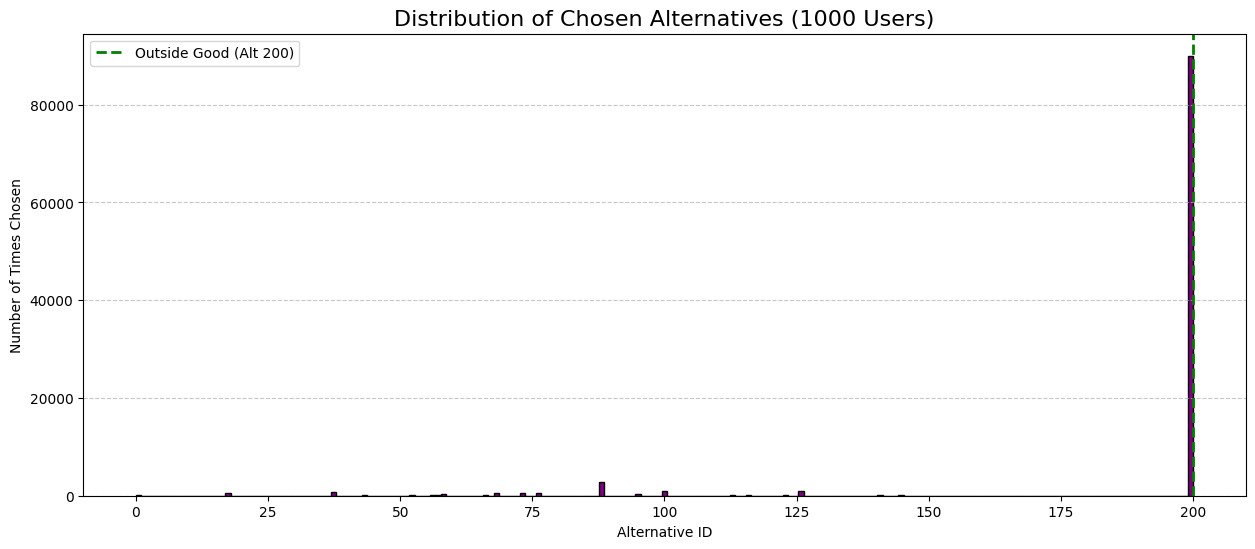

In [203]:
import cudf
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.hist(choices.get(), bins=n_alternatives_total, color='purple', edgecolor='black')
plt.title('Distribution of Chosen Alternatives (1000 Users)', fontsize=16)
plt.xlabel('Alternative ID')
plt.ylabel('Number of Times Chosen')
plt.axvline(n_alternatives, color='green', linestyle='--', linewidth=2, label=f'Outside Good (Alt {n_alternatives})')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Using the kernel ( optional)